In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, GridSearchCV
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import SVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)

df_weather = pd.read_csv("data/weather_classification_data.csv")
df_clothes = pd.read_csv("data/final_test.csv")

# Задание 1

In [3]:
categorical_cols = ['Cloud Cover', 'Season', 'Location']
label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    df_weather[col + '_encoded'] = le.fit_transform(df_weather[col])
    label_encoders[col] = le

target_le = LabelEncoder()
df_weather['Weather_Type_encoded'] = target_le.fit_transform(df_weather['Weather Type'])

feature_cols = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
                'Atmospheric Pressure', 'UV Index', 'Visibility (km)',
                'Cloud Cover_encoded', 'Season_encoded', 'Location_encoded']

X = df_weather[feature_cols]
y = df_weather['Weather_Type_encoded']

numeric_cols = ['Temperature', 'Humidity', 'Wind Speed', 'Precipitation (%)',
                'Atmospheric Pressure', 'UV Index', 'Visibility (km)']

scaler = StandardScaler()
X_numeric_scaled = scaler.fit_transform(X[numeric_cols])

encoded_cols = ['Cloud Cover_encoded', 'Season_encoded', 'Location_encoded']
X_scaled = np.hstack([X_numeric_scaled, X[encoded_cols].values])

X_train, X_test, y_train, y_test = train_test_split(
    X_scaled, y, test_size=0.2, random_state=42, stratify=y
)

In [4]:
k_values = range(1, 21)
knn_scores = []

for k in k_values:
    knn = KNeighborsClassifier(n_neighbors=k)
    knn.fit(X_train, y_train)
    knn_scores.append(accuracy_score(y_test, knn.predict(X_test)))

best_k = k_values[np.argmax(knn_scores)]
knn_best = KNeighborsClassifier(n_neighbors=best_k)
knn_best.fit(X_train, y_train)
y_pred_knn = knn_best.predict(X_test)

accuracy_knn = accuracy_score(y_test, y_pred_knn)
precision_knn = precision_score(y_test, y_pred_knn, average='weighted')
recall_knn = recall_score(y_test, y_pred_knn, average='weighted')
f1_knn = f1_score(y_test, y_pred_knn, average='weighted')

print(f"k-NN (k={best_k}): Accuracy={accuracy_knn:.4f}, F1={f1_knn:.4f}")

k-NN (k=3): Accuracy=0.9023, F1=0.9029


In [5]:
svm_params = {'C': [0.1, 1, 10], 'kernel': ['rbf', 'linear']}
svm_grid = GridSearchCV(SVC(random_state=42), svm_params, cv=5, scoring='accuracy')
svm_grid.fit(X_train, y_train)

svm_best = svm_grid.best_estimator_
y_pred_svm = svm_best.predict(X_test)

accuracy_svm = accuracy_score(y_test, y_pred_svm)
precision_svm = precision_score(y_test, y_pred_svm, average='weighted')
recall_svm = recall_score(y_test, y_pred_svm, average='weighted')
f1_svm = f1_score(y_test, y_pred_svm, average='weighted')

print(f"SVM: Accuracy={accuracy_svm:.4f}, F1={f1_svm:.4f}")

SVM: Accuracy=0.9087, F1=0.9090


In [6]:
rf_params = {
    'n_estimators': [50, 100, 200],
    'max_depth': [None, 10, 20],
    'min_samples_split': [2, 5, 10]
}
rf_grid = GridSearchCV(RandomForestClassifier(random_state=42), rf_params, cv=5, scoring='accuracy', n_jobs=-1)
rf_grid.fit(X_train, y_train)

rf_best = rf_grid.best_estimator_
y_pred_rf = rf_best.predict(X_test)

accuracy_rf = accuracy_score(y_test, y_pred_rf)
precision_rf = precision_score(y_test, y_pred_rf, average='weighted')
recall_rf = recall_score(y_test, y_pred_rf, average='weighted')
f1_rf = f1_score(y_test, y_pred_rf, average='weighted')

print(f"Random Forest: Accuracy={accuracy_rf:.4f}, F1={f1_rf:.4f}")

Random Forest: Accuracy=0.9152, F1=0.9156


       Модель  Точность (A)  Точность (P)  Полнота  F1-мера
         k-NN      0.902273      0.905081 0.902273 0.902916
          SVM      0.908712      0.910147 0.908712 0.909030
Случайный лес      0.915152      0.916826 0.915152 0.915555


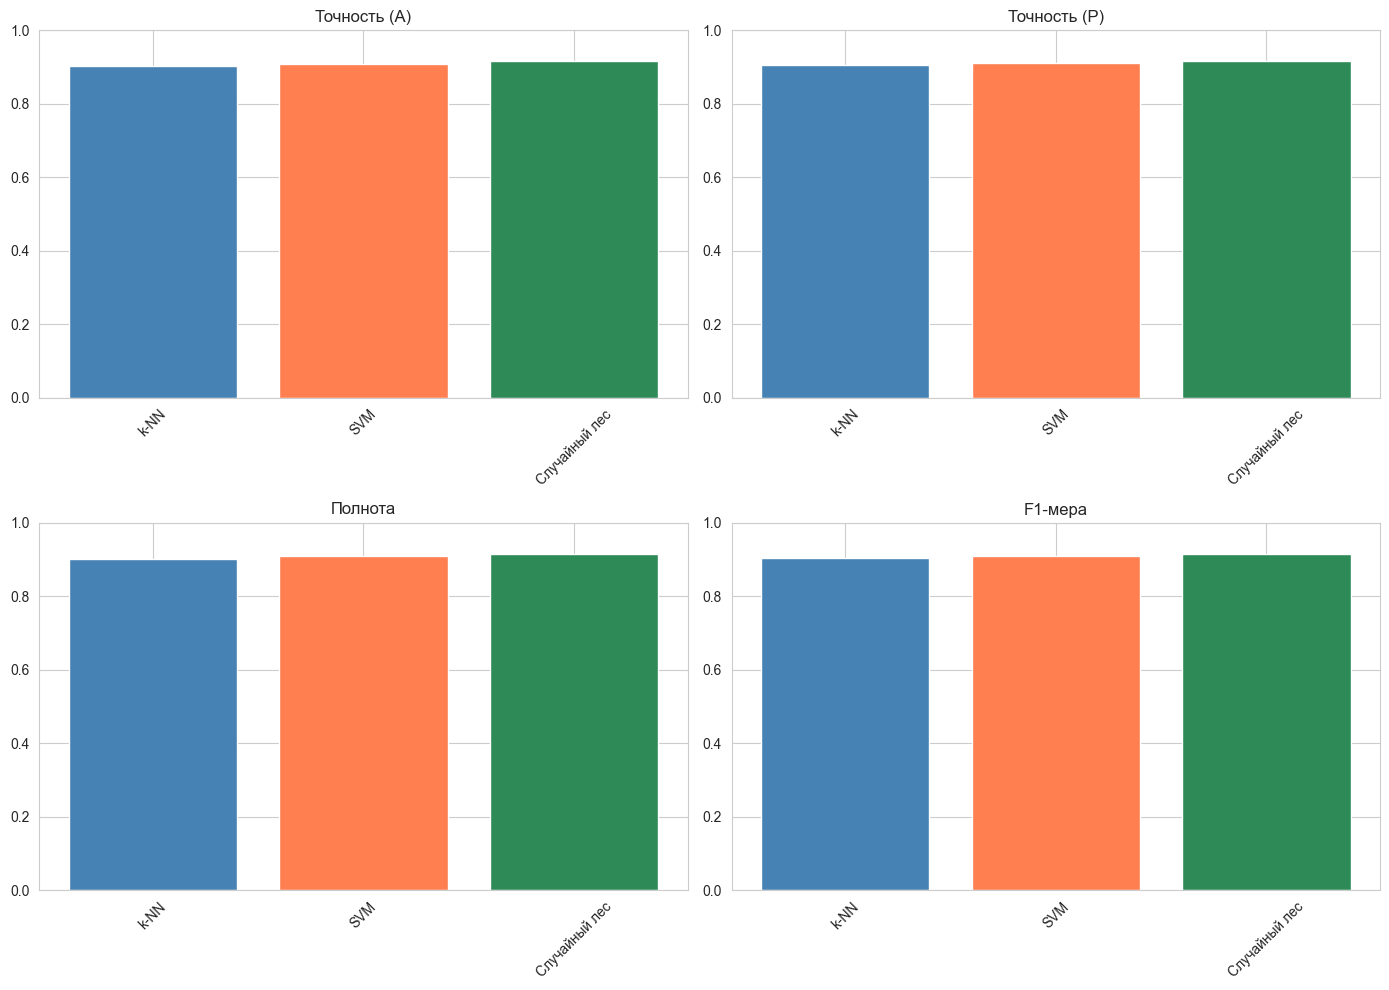

In [14]:
results = pd.DataFrame([
    ['k-NN', accuracy_knn, precision_knn, recall_knn, f1_knn],
    ['SVM', accuracy_svm, precision_svm, recall_svm, f1_svm],
    ['Случайный лес', accuracy_rf, precision_rf, recall_rf, f1_rf]
], columns=['Модель', 'Точность (A)', 'Точность (P)', 'Полнота', 'F1-мера'])

print(results.to_string(index=False))

fig, axes = plt.subplots(2, 2, figsize=(14, 10))
metrics = ['Точность (A)', 'Точность (P)', 'Полнота', 'F1-мера']
colors = ['steelblue', 'coral', 'seagreen', 'purple']

for i, metric in enumerate(metrics):
    row, col = i // 2, i % 2
    axes[row, col].bar(results['Модель'], results[metric], color=colors)
    axes[row, col].set_title(metric)
    axes[row, col].set_ylim(0, 1)
    axes[row, col].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

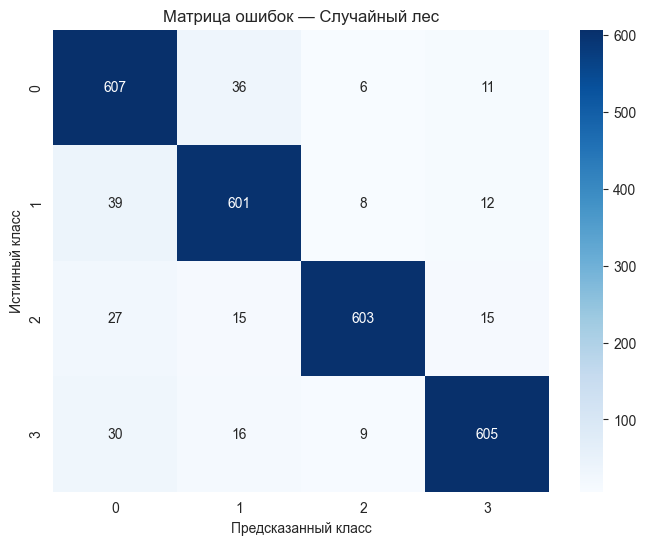

In [15]:
best_idx = results['Точность (A)'].idxmax()
best_model = results.loc[best_idx, 'Модель']
preds = [y_pred_knn, y_pred_svm, y_pred_rf][best_idx]

cm = confusion_matrix(y_test, preds)
plt.figure(figsize=(8, 6))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
plt.title(f'Матрица ошибок — {best_model}')
plt.xlabel('Предсказанный класс')
plt.ylabel('Истинный класс')
plt.show()

# Задание *

In [10]:
for col in df_clothes.columns:
    if df_clothes[col].isna().sum() > 0:
        if pd.api.types.is_numeric_dtype(df_clothes[col]):
            df_clothes[col] = df_clothes[col].fillna(df_clothes[col].median())
        else:
            df_clothes[col] = df_clothes[col].fillna(df_clothes[col].mode()[0])

df_clothes['bmi'] = df_clothes['weight'] / (df_clothes['height'] / 100) ** 2
df_clothes['weight_squared'] = df_clothes['weight'] ** 2
df_clothes['height_squared'] = df_clothes['height'] ** 2
df_clothes['weight_height_ratio'] = df_clothes['weight'] / df_clothes['height']

size_order = ['S', 'M', 'L', 'XL', 'XXL']
size_to_num = {size: i for i, size in enumerate(size_order)}
df_clothes['size_encoded'] = df_clothes['size'].map(size_to_num)
df_clothes = df_clothes.dropna(subset=['size_encoded'])

feature_cols_c = ['weight', 'age', 'height', 'bmi', 'weight_squared', 'height_squared', 'weight_height_ratio']
X_c = df_clothes[feature_cols_c]
y_c = df_clothes['size_encoded']

scaler_c = StandardScaler()
X_c_scaled = scaler_c.fit_transform(X_c)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c_scaled, y_c, test_size=0.2, random_state=42, stratify=y_c
)

In [16]:
param_grid_c = {
    'n_estimators': [50, 100, 200],
    'max_depth': [5, 10, 15, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 4]
}

grid_c = GridSearchCV(RandomForestClassifier(random_state=42), param_grid_c, cv=3, scoring='accuracy', n_jobs=-1)
grid_c.fit(X_train_c, y_train_c)

best_rf_c = grid_c.best_estimator_
y_pred_c = best_rf_c.predict(X_test_c)

accuracy_c = accuracy_score(y_test_c, y_pred_c)
print(f"Точность модели: {accuracy_c:.4f}")

if accuracy_c >= 0.7:
    print("Цель достигнута: точность >= 0.7")
else:
    print(f"Точность {accuracy_c:.4f} < 0.7, требуется доработка")

Точность модели: 0.5409
Точность 0.5409 < 0.7, требуется доработка


In [18]:
# Удаление выбросов по весу и росту
q_low = df_clothes['weight'].quantile(0.01)
q_high = df_clothes['weight'].quantile(0.99)
df_clothes = df_clothes[(df_clothes['weight'] >= q_low) & (df_clothes['weight'] <= q_high)]

q_low_h = df_clothes['height'].quantile(0.01)
q_high_h = df_clothes['height'].quantile(0.99)
df_clothes = df_clothes[(df_clothes['height'] >= q_low_h) & (df_clothes['height'] <= q_high_h)]

# Удаление некорректного BMI
df_clothes = df_clothes[df_clothes['bmi'] > 10]

# Дополнительные признаки
df_clothes['age_group'] = pd.cut(df_clothes['age'], bins=[0, 25, 35, 45, 60, 100], labels=[0, 1, 2, 3, 4])
df_clothes['bmi_category'] = pd.cut(df_clothes['bmi'], bins=[0, 18.5, 25, 30, 100], labels=[0, 1, 2, 3])

# Кодирование новых признаков
df_clothes['age_group'] = df_clothes['age_group'].astype(float)
df_clothes['bmi_category'] = df_clothes['bmi_category'].astype(float)

# Обновлённый список признаков
feature_cols_c = ['weight', 'age', 'height', 'bmi', 'weight_squared', 'height_squared',
                  'weight_height_ratio', 'age_group', 'bmi_category']

# Проверка на NaN после добавления категорий
df_clothes = df_clothes.dropna(subset=feature_cols_c + ['size_encoded'])

X_c = df_clothes[feature_cols_c]
y_c = df_clothes['size_encoded']

scaler_c = StandardScaler()
X_c_scaled = scaler_c.fit_transform(X_c)

# Балансировка классов через class_weight
X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c_scaled, y_c, test_size=0.2, random_state=42, stratify=y_c
)

print(f"Размер после очистки: {df_clothes.shape[0]} строк")
print(f"Распределение классов после очистки:\n{pd.Series(y_c).value_counts().sort_index().to_dict()}")

Размер после очистки: 85875 строк
Распределение классов после очистки:
{0.0: 21136, 1.0: 29297, 2.0: 17215, 3.0: 18164, 4.0: 63}


In [19]:
param_grid_c = {
    'n_estimators': [100, 200, 300],
    'max_depth': [10, 15, 20, None],
    'min_samples_split': [2, 5],
    'min_samples_leaf': [1, 2],
    'class_weight': ['balanced', 'balanced_subsample']
}

grid_c = GridSearchCV(
    RandomForestClassifier(random_state=42),
    param_grid_c,
    cv=5,
    scoring='accuracy',
    n_jobs=-1,
    verbose=1
)
grid_c.fit(X_train_c, y_train_c)

best_rf_c = grid_c.best_estimator_
y_pred_c = best_rf_c.predict(X_test_c)

accuracy_c = accuracy_score(y_test_c, y_pred_c)
print(f"Точность модели: {accuracy_c:.4f}")
print(f"Лучшие параметры: {grid_c.best_params_}")

if accuracy_c >= 0.7:
    print("Цель достигнута: точность >= 0.7")
else:
    print(f"Точность {accuracy_c:.4f} < 0.7")

Fitting 5 folds for each of 96 candidates, totalling 480 fits
Точность модели: 0.5221
Лучшие параметры: {'class_weight': 'balanced', 'max_depth': 15, 'min_samples_leaf': 2, 'min_samples_split': 5, 'n_estimators': 100}
Точность 0.5221 < 0.7


In [20]:
# Удаление выбросов
for col in ['weight', 'height', 'age']:
    q_low = df_clothes[col].quantile(0.02)
    q_high = df_clothes[col].quantile(0.98)
    df_clothes = df_clothes[(df_clothes[col] >= q_low) & (df_clothes[col] <= q_high)]

# Новые признаки
df_clothes['bmi'] = df_clothes['weight'] / (df_clothes['height'] / 100) ** 2
df_clothes['weight_log'] = np.log1p(df_clothes['weight'])
df_clothes['height_log'] = np.log1p(df_clothes['height'])
df_clothes['weight_height_interaction'] = df_clothes['weight'] * df_clothes['height']
df_clothes['bmi_squared'] = df_clothes['bmi'] ** 2
df_clothes['age_squared'] = df_clothes['age'] ** 2

# Группировка возраста и BMI
df_clothes['age_bin'] = pd.cut(df_clothes['age'], bins=5, labels=False)
df_clothes['bmi_bin'] = pd.cut(df_clothes['bmi'], bins=5, labels=False)

# Кодирование размера
size_order = ['S', 'M', 'L', 'XL', 'XXL']
size_to_num = {size: i for i, size in enumerate(size_order)}
df_clothes['size_encoded'] = df_clothes['size'].map(size_to_num)
df_clothes = df_clothes.dropna(subset=['size_encoded'])

# Признаки
feature_cols_c = ['weight', 'height', 'age', 'bmi', 'weight_log', 'height_log',
                  'weight_height_interaction', 'bmi_squared', 'age_squared',
                  'age_bin', 'bmi_bin']

X_c = df_clothes[feature_cols_c]
y_c = df_clothes['size_encoded']

# Удаление строк с бесконечными значениями
X_c = X_c.replace([np.inf, -np.inf], np.nan).dropna()
y_c = y_c.loc[X_c.index]

scaler_c = StandardScaler()
X_c_scaled = scaler_c.fit_transform(X_c)

X_train_c, X_test_c, y_train_c, y_test_c = train_test_split(
    X_c_scaled, y_c, test_size=0.2, random_state=42, stratify=y_c
)

print(f"Размер после очистки: {X_c.shape[0]} строк")
print(f"Распределение классов:\n{pd.Series(y_c).value_counts().sort_index().to_dict()}")

Размер после очистки: 78615 строк
Распределение классов:
{0: 18887, 1: 27486, 2: 15939, 3: 16254, 4: 49}


In [21]:
from xgboost import XGBClassifier

param_grid_c = {
    'n_estimators': [100, 200, 300],
    'max_depth': [3, 5, 7],
    'learning_rate': [0.05, 0.1, 0.2],
    'subsample': [0.8, 1.0],
    'colsample_bytree': [0.8, 1.0]
}

xgb = XGBClassifier(random_state=42, eval_metric='mlogloss')

grid_c = GridSearchCV(
    xgb, param_grid_c, cv=5, scoring='accuracy', n_jobs=-1, verbose=1
)
grid_c.fit(X_train_c, y_train_c)

best_xgb = grid_c.best_estimator_
y_pred_c = best_xgb.predict(X_test_c)

accuracy_c = accuracy_score(y_test_c, y_pred_c)
print(f"Точность модели XGBoost: {accuracy_c:.4f}")
print(f"Лучшие параметры: {grid_c.best_params_}")

if accuracy_c >= 0.7:
    print("Цель достигнута!")
else:
    print(f"Точность {accuracy_c:.4f} < 0.7")

Fitting 5 folds for each of 108 candidates, totalling 540 fits
Точность модели XGBoost: 0.5304
Лучшие параметры: {'colsample_bytree': 1.0, 'learning_rate': 0.1, 'max_depth': 7, 'n_estimators': 100, 'subsample': 0.8}
Точность 0.5304 < 0.7


К сожалению поставленной цели не удалось достичь(